<div >
    <img src = "../banner.jpg" />
</div>

<a href="https://colab.research.google.com/github/ignaciomsarmiento/BDML_2026_20/blob/main/Lecture14/02_CNN_Satelital.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN sobre imágenes satelitales

El objetivo es usar transfer learning sobre las imagenes de **EuroSAT** (Helber et al., 2019): 27.000 imágenes de Sentinel-2 de $64 \times 64$ píxeles, cada una etiquetada con uno de 10 usos del suelo (cultivos, bosque, autopista, residencial, río, \dots).



## Llamando las librerías

In [1]:
install.packages("pacman") #Correr esta linea en Google Colab

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [2]:
require("pacman")
p_load("tidyverse", "keras3", "glmnet", "abind")

Loading required package: pacman



In [3]:
# Verificar si TensorFlow detecta y está utilizando la GPU
tf <- reticulate::import("tensorflow")
gpus <- tf$config$list_physical_devices("GPU")

if (length(gpus) > 0) {
  cat("¡Excelente! Habemus GPU\n")
  print(gpus)
} else {
  cat("=( GPUs.\n")
}

¡Excelente! Habemus GPU
[[1]]
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')



In [4]:
set_random_seed(20261111)  # fija la semilla de R, Python y TensorFlow

## Los datos

Descargamos la versión RGB de EuroSAT desde Zenodo (unos 95 MB) y la descomprimimos. Cada clase viene en su propia carpeta.

In [5]:
options(timeout = 900)

if (!file.exists("EuroSAT_RGB.zip")) {
  download.file("https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip",
                destfile = "EuroSAT_RGB.zip", mode = "wb")
}
if (!dir.exists("EuroSAT_RGB")) unzip("EuroSAT_RGB.zip")

clases <- sort(list.dirs("EuroSAT_RGB", full.names = FALSE, recursive = FALSE))
sapply(clases, function(cl) length(list.files(file.path("EuroSAT_RGB", cl))))

AnnualCrop               Forest HerbaceousVegetation 
                3000                 3000                 3000 
             Highway           Industrial              Pasture 
                2500                 2500                 2000 
       PermanentCrop          Residential                River 
                2500                 3000                 2500 
             SeaLake 
                3000

`image_dataset_from_directory()` lee las imágenes por lotes desde las carpetas y usa el nombre de la carpeta como etiqueta. Reservamos el 20% para validación.

In [6]:
datos <- image_dataset_from_directory(
  "EuroSAT_RGB",
  validation_split = 0.2,
  subset           = "both",
  seed             = 20261111,
  image_size       = c(64, 64),
  batch_size       = 64
)
train_ds <- datos[[1]]
val_ds   <- datos[[2]]

Miremos algunas imágenes. Cada imagen es un arreglo de $64 \times 64 \times 3$: alto, ancho y tres canales (rojo, verde, azul).

In [7]:
lote <- reticulate::iter_next(val_ds$as_numpy_iterator())
dim(lote[[1]][1,,,])

[1] 64 64  3

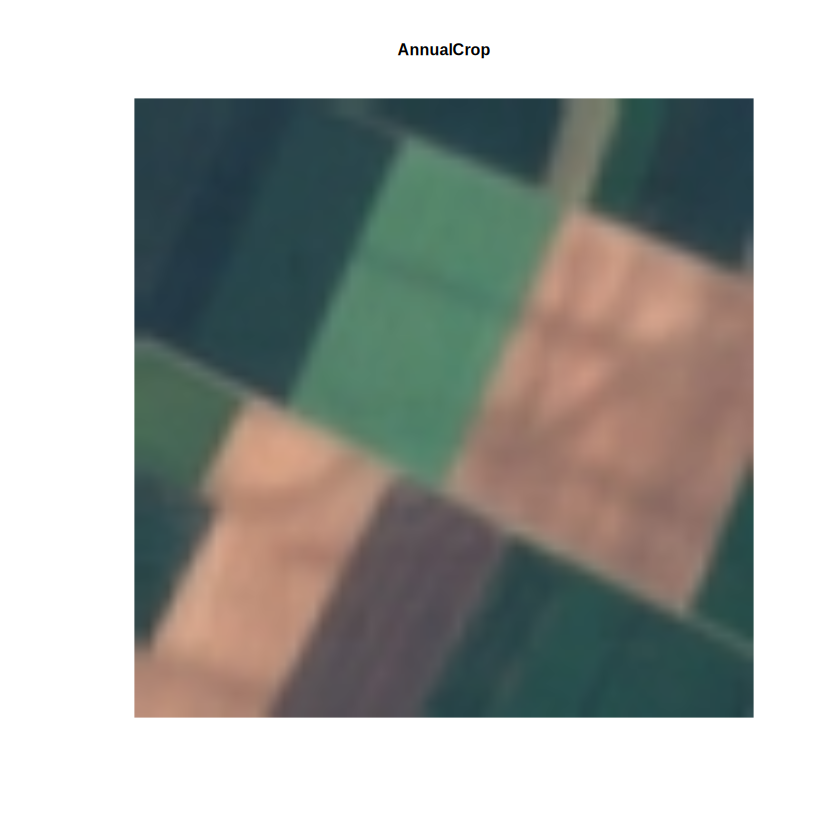

In [8]:
i<-4
plot(as.raster(lote[[1]][i, , , ] / 255))
title(clases[lote[[2]][i] + 1], cex.main = 0.8)

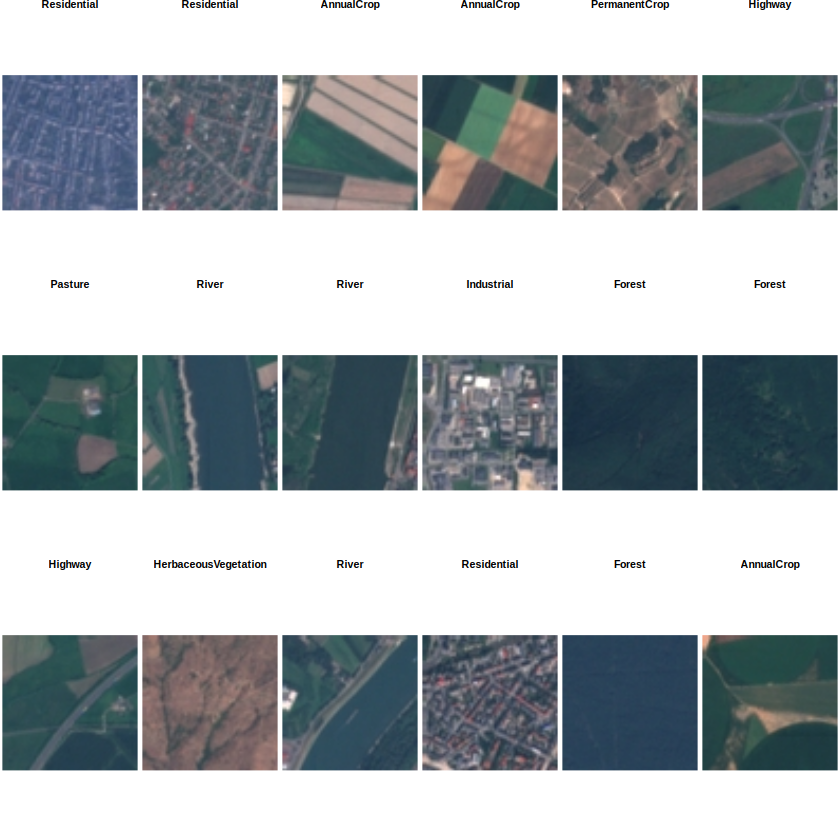

In [9]:
# Varios

par(mfrow = c(3, 6), mar = c(0.15, 0.15, 0.5, 0.15))
for (i in 1:18) {
  plot(as.raster(lote[[1]][i, , , ] / 255))
  title(clases[lote[[2]][i] + 1], cex.main = 0.8)
}

## 1. Una CNN pequeña desde cero

La misma arquitectura de la clase pasada, ahora con tres canales de entrada. `layer_rescaling()` lleva los píxeles de $[0, 255]$ a $[0, 1]$ dentro del modelo.

In [10]:
cnn <- keras_model_sequential(input_shape = c(64, 64, 3)) %>%
  layer_rescaling(scale = 1 / 255) %>%
  layer_conv_2d(filters = 32, kernel_size = c(3, 3), activation = "relu") %>%
  layer_max_pooling_2d(pool_size = c(2, 2)) %>%
  layer_conv_2d(filters = 64, kernel_size = c(3, 3), activation = "relu") %>%
  layer_max_pooling_2d(pool_size = c(2, 2)) %>%
  layer_conv_2d(filters = 64, kernel_size = c(3, 3), activation = "relu") %>%
  layer_max_pooling_2d(pool_size = c(2, 2)) %>%
  layer_flatten() %>%
  layer_dropout(rate = 0.5) %>%
  layer_dense(units = 128, activation = "relu") %>%
  layer_dense(units = 10, activation = "softmax")

cnn %>% compile(optimizer = "adam",
                loss = "sparse_categorical_crossentropy",  # etiquetas enteras 0-9, no one-hot
                metrics = "accuracy")
summary(cnn)

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)             │ (None, 64, 64, 3)        │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d (Conv2D)                   │ (None, 62, 62, 32)       │           896 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)      │ (None, 31, 31, 32)       │             0 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)                 │ (None, 29, 29, 64)       │        18,496 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)    │ (None, 14, 14, 64)       │             0 │
├───────

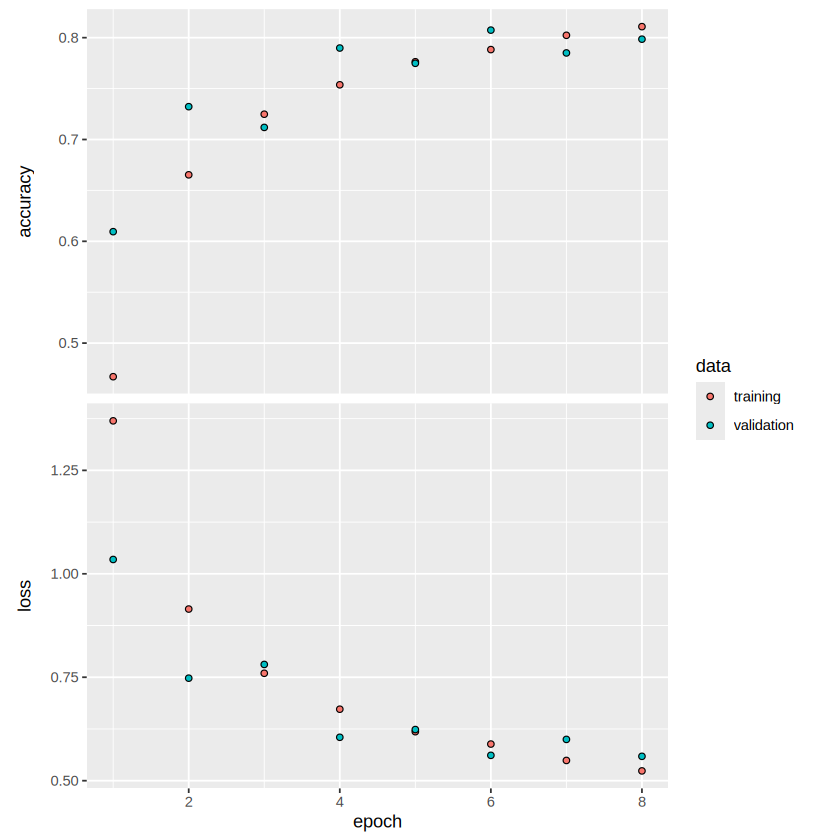

In [11]:
historia_cnn <- cnn %>% fit(train_ds, validation_data = val_ds, epochs = 8, verbose = 2)
plot(historia_cnn)

## 2. Transfer learning

MobileNetV2 es una CNN entrenada con 1,2 millones de imágenes de [ImageNet](https://en.wikipedia.org/wiki/ImageNet).

Pero esta red, nunca vio una imagen satelital. Sin embargo sus primeras capas detectan bordes, texturas y formas que sirven para cualquier imagen.

Vamos a hacer lo siguiente:
- `include_top = FALSE`: le quitamos la capa final, que clasificaba las 1.000 clases de ImageNet.
- `base$trainable <- FALSE`: **congelamos** sus pesos. Solo entrenamos la capa nueva.
- MobileNetV2 espera imágenes de al menos $96 \times 96$ con píxeles en $[-1, 1]$, así que tenemos que agrandar las imágenes y reescalarlas dentro del modelo (esto obviamente nos introduce ruido).

In [12]:
base <- application_mobilenet_v2(include_top = FALSE, weights = "imagenet",
                                  input_shape = c(96, 96, 3))
base$trainable <- FALSE

entrada <- keras_input(shape = c(64, 64, 3))
salida <- entrada %>%
  layer_resizing(96, 96) %>%
  layer_rescaling(scale = 1 / 127.5, offset = -1) %>%
  base(training = FALSE) %>%
  layer_global_average_pooling_2d() %>%
  layer_dropout(rate = 0.2) %>%
  layer_dense(units = 10, activation = "softmax")

transfer <- keras_model(entrada, salida)
transfer %>% compile(optimizer = "adam",
                     loss = "sparse_categorical_crossentropy",
                     metrics = "accuracy")
summary(transfer)

Model: "functional_11"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape           ┃     Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 64, 64, 3)      │           0 │   -   │
├───────────────────────────────┼────────────────────────┼─────────────┼───────┤
│ resizing (Resizing)           │ (None, 96, 96, 3)      │           0 │   -   │
├───────────────────────────────┼────────────────────────┼─────────────┼───────┤
│ rescaling_1 (Rescaling)       │ (None, 96, 96, 3)      │           0 │   -   │
├───────────────────────────────┼────────────────────────┼─────────────┼───────┤
│ mobilenetv2_1.00_96           │ (None, 3, 3, 1280)     │   2,257,984 │   N   │
│ (Functional)                  │                        │             │       │
├───────────────────────────────┼────────────────────────┼─────────────┼───────┤
│ glo

La red tiene más de 2 millones de parámetros, pero solo unos 12.800 son entrenables (la capa densa final: $1.280 \times 10 + 10$).

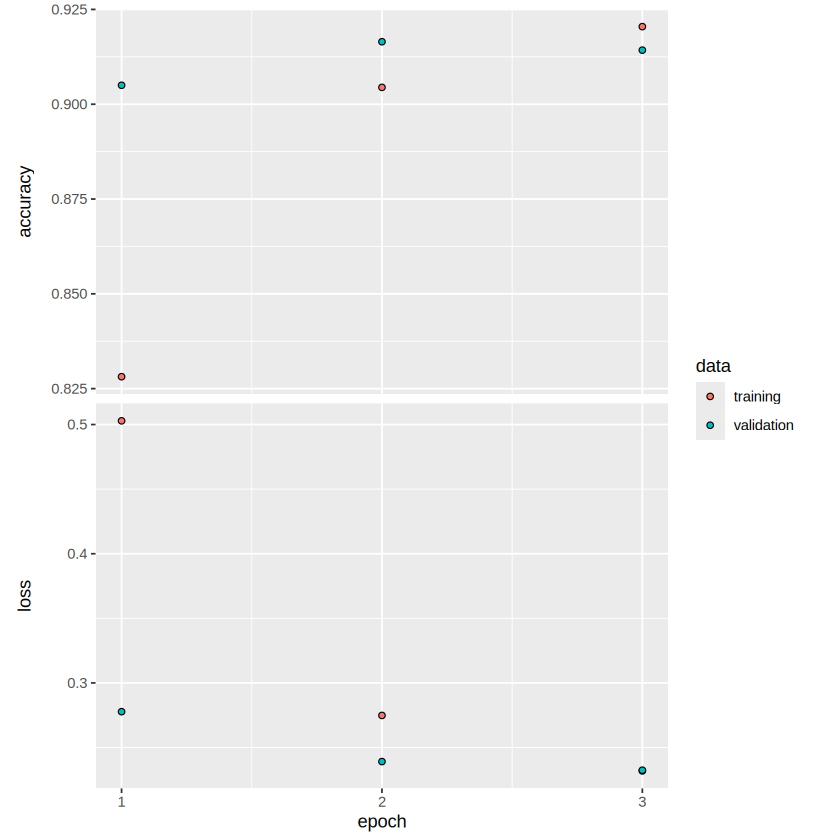

In [13]:
historia_transfer <- transfer %>% fit(train_ds, validation_data = val_ds, epochs = 3, verbose = 2)
plot(historia_transfer)

In [14]:
acc_congelada <- evaluate(transfer, val_ds, verbose = 0)$accuracy

tibble(
  Modelo     = c("CNN desde cero", "Transfer learning (MobileNetV2)"),
  Epocas     = c(8, 3),
  Accuracy   = c(evaluate(cnn, val_ds, verbose = 0)$accuracy,
                 acc_congelada)
)

Modelo,Epocas,Accuracy
<chr>,<dbl>,<dbl>
CNN desde cero,8,0.7985185
Transfer learning (MobileNetV2),3,0.9142593


## 3. Fine-tuning

Hasta ahora la red preentrenada quedó congelada. Que pasa si ahora permitimos que las ultimas capas se ajusten un poco, pero muy poco, para que los pesos no se alejen mucho de su punto de partida.

Para ello arrancamos desde los parámetros ya aprendidos ($\theta_0$), con una tasa de aprendizaje pequeña y pocas épocas.

In [21]:
length(base$layers)

[1] 154

In [22]:
# Nombres de todas las capas
sapply(base$layers, function(capa) capa$name)



[1] "input_layer_1"                "Conv1"                       
  [3] "bn_Conv1"                     "Conv1_relu"                  
  [5] "expanded_conv_depthwise"      "expanded_conv_depthwise_BN"  
  [7] "expanded_conv_depthwise_relu" "expanded_conv_project"       
  [9] "expanded_conv_project_BN"     "block_1_expand"              
 [11] "block_1_expand_BN"            "block_1_expand_relu"         
 [13] "block_1_pad"                  "block_1_depthwise"           
 [15] "block_1_depthwise_BN"         "block_1_depthwise_relu"      
 [17] "block_1_project"              "block_1_project_BN"          
 [19] "block_2_expand"               "block_2_expand_BN"           
 [21] "block_2_expand_relu"          "block_2_depthwise"           
 [23] "block_2_depthwise_BN"         "block_2_depthwise_relu"      
 [25] "block_2_project"              "block_2_project_BN"          
 [27] "block_2_add"                  "block_3_expand"              
 [29] "block_3_expand_BN"            "block_3_expand_relu"         
 [31] "block_3_pad"                  "block_3_depthwise"           
 [33] "block_3_depthwise_BN"         "block_3_depthwise_relu"      
 [35] "block_3_project"              "block_3_project_BN"          
 [37] "block_4_expand"               "block_4_expand_BN"           
 [39] "block_4_expand_relu"          "block_4_depthwise"           
 [41] "block_4_depthwise_BN"         "block_4_depthwise_relu"      
 [43] "block_4_project"              "block_4_project_BN"          
 [45] "block_4_add"                  "block_5_expand"              
 [47] "block_5_expand_BN"            "block_5_expand_relu"         
 [49] "block_5_depthwise"            "block_5_depthwise_BN"        
 [51] "block_5_depthwise_relu"       "block_5_project"             
 [53] "block_5_project_BN"           "block_5_add"                 
 [55] "block_6_expand"               "block_6_expand_BN"           
 [57] "block_6_expand_relu"          "block_6_pad"                 
 [59] "block_6_depthwise"            "block_6_depthwise_BN"        
 [61] "block_6_depthwise_relu"       "block_6_project"             
 [63] "block_6_project_BN"           "block_7_expand"              
 [65] "block_7_expand_BN"            "block_7_expand_relu"         
 [67] "block_7_depthwise"            "block_7_depthwise_BN"        
 [69] "block_7_depthwise_relu"       "block_7_project"             
 [71] "block_7_project_BN"           "block_7_add"                 
 [73] "block_8_expand"               "block_8_expand_BN"           
 [75] "block_8_expand_relu"          "block_8_depthwise"           
 [77] "block_8_depthwise_BN"         "block_8_depthwise_relu"      
 [79] "block_8_project"              "block_8_project_BN"          
 [81] "block_8_add"                  "block_9_expand"              
 [83] "block_9_expand_BN"            "block_9_expand_relu"         
 [85] "block_9_depthwise"            "block_9_depthwise_BN"        
 [87] "block_9_depthwise_relu"       "block_9_project"             
 [89] "block_9_project_BN"           "block_9_add"                 
 [91] "block_10_expand"              "block_10_expand_BN"          
 [93] "block_10_expand_relu"         "block_10_depthwise"          
 [95] "block_10_depthwise_BN"        "block_10_depthwise_relu"     
 [97] "block_10_project"             "block_10_project_BN"         
 [99] "block_11_expand"              "block_11_expand_BN"          
[101] "block_11_expand_relu"         "block_11_depthwise"          
[103] "block_11_depthwise_BN"        "block_11_depthwise_relu"     
[105] "block_11_project"             "block_11_project_BN"         
[107] "block_11_add"                 "block_12_expand"             
[109] "block_12_expand_BN"           "block_12_expand_relu"        
[111] "block_12_depthwise"           "block_12_depthwise_BN"       
[113] "block_12_depthwise_relu"      "block_12_project"            
[115] "block_12_project_BN"          "block_12_add"                
[117] "block_13_expand"              "block_13_expand_BN" 

In [23]:
# Nombres de las últimas 30 capas
sapply(tail(base$layers, 30), function(capa) capa$name)

[1] "block_13_project_BN"     "block_14_expand"        
 [3] "block_14_expand_BN"      "block_14_expand_relu"   
 [5] "block_14_depthwise"      "block_14_depthwise_BN"  
 [7] "block_14_depthwise_relu" "block_14_project"       
 [9] "block_14_project_BN"     "block_14_add"           
[11] "block_15_expand"         "block_15_expand_BN"     
[13] "block_15_expand_relu"    "block_15_depthwise"     
[15] "block_15_depthwise_BN"   "block_15_depthwise_relu"
[17] "block_15_project"        "block_15_project_BN"    
[19] "block_15_add"            "block_16_expand"        
[21] "block_16_expand_BN"      "block_16_expand_relu"   
[23] "block_16_depthwise"      "block_16_depthwise_BN"  
[25] "block_16_depthwise_relu" "block_16_project"       
[27] "block_16_project_BN"     "Conv_1"                 
[29] "Conv_1_bn"               "out_relu"

In [24]:
summary(base)

Model: "mobilenetv2_1.00_96"
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)       ┃ Output Shape     ┃    Param # ┃ Connected to    ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1      │ (None, 96, 96,   │          0 │ -               │   -   │
│ (InputLayer)       │ 3)               │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ Conv1 (Conv2D)     │ (None, 48, 48,   │        864 │ input_layer_1[… │   N   │
│                    │ 32)              │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤
│ bn_Conv1           │ (None, 48, 48,   │        128 │ Conv1[0][0]     │   N   │
│ (BatchNormalizati… │ 32)              │            │                 │       │
├────────────────────┼──────────────────┼────────────┼─────────────────┼───────┤

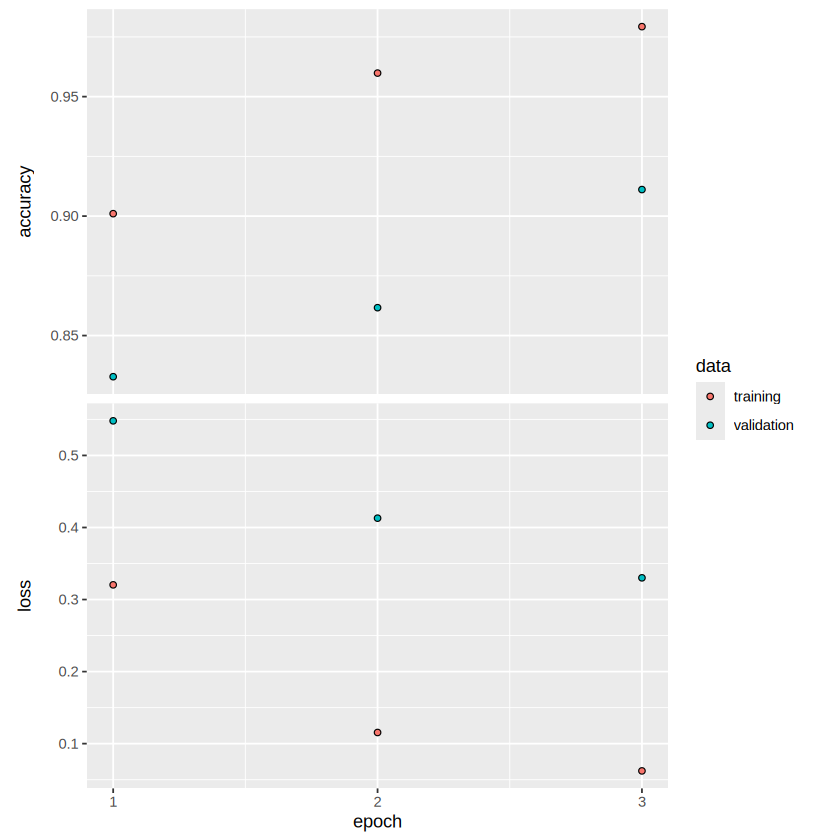

In [15]:
base$trainable <- TRUE
capas <- base$layers
for (capa in head(capas, -30)) capa$trainable <- FALSE   # solo las últimas 30 capas se mueven

transfer %>% compile(optimizer = optimizer_adam(learning_rate = 1e-4),
                     loss = "sparse_categorical_crossentropy",
                     metrics = "accuracy")

historia_fine <- transfer %>% fit(train_ds, validation_data = val_ds, epochs = 3, verbose = 2)
plot(historia_fine)

In [16]:
tibble(
  Modelo   = c("CNN desde cero", "Transfer learning, base congelada", "Fine-tuning"),
  Epocas   = c("8", "3", "3 + 3"),
  Accuracy = c(evaluate(cnn, val_ds, verbose = 0)$accuracy,
               acc_congelada,
               evaluate(transfer, val_ds, verbose = 0)$accuracy)
)

Modelo,Epocas,Accuracy
<chr>,<chr>,<dbl>
CNN desde cero,8,0.7985185
"Transfer learning, base congelada",3,0.9142593
Fine-tuning,3 + 3,0.9111111


Una leccion interesante al soltar los pesos ganamos ajuste y empezamos a sobreajustar.


## 4. La imagen como vector de rasgos

La penúltima capa de la red preentrenada resume cada imagen en un vector de 1.280 números.

Al ser un vector, nada nos impide que lo usemos como insumo en **cualquier** modelo

Entonces, extraigamos esos (con ayuda de claude) y entrenemos el modelo

In [17]:
extractor <- keras_model(entrada, entrada %>%
  layer_resizing(96, 96) %>%
  layer_rescaling(scale = 1 / 127.5, offset = -1) %>%
  base(training = FALSE) %>%
  layer_global_average_pooling_2d())

extraer_rasgos <- function(ds, n_lotes) {
  it <- ds$as_numpy_iterator()
  lotes <- map(seq_len(n_lotes), function(i) {
    l <- reticulate::iter_next(it)
    list(x = predict(extractor, l[[1]], verbose = 0), y = l[[2]])
  })
  list(x = do.call(rbind, map(lotes, "x")), y = unlist(map(lotes, "y")))
}

rasgos_train <- extraer_rasgos(train_ds, 50)   # 3.200 imágenes
rasgos_test  <- extraer_rasgos(val_ds, 20)     # 1.280 imágenes
dim(rasgos_train$x)

[1] 3200 1280

Dado que tenemos 1.280 variables y 3.200 observaciones, el potencial de sobreajuste es grande. Para esto vamos a regularizar:

In [18]:
ridge <- cv.glmnet(rasgos_train$x, factor(rasgos_train$y), family = "multinomial",
                   alpha = 0, nfolds = 5)

y_hat <- predict(ridge, rasgos_test$x, s = "lambda.min", type = "class")
mean(as.numeric(y_hat) == rasgos_test$y)

[1] 0.9335938

Una modelo sencillo, pero regularizado, sobre los rasgos de una red que nunca vio una imagen satelital clasifica bastante bien el uso del suelo, con solo 3.200 imágenes etiquetadas.  Esto es potencialmente super útil en economia donde solemos tener pocos "labels"

# Caveat emptor: datos espaciales

Las imágenes de EuroSAT RGB no traen coordenadas, así que aquí no podemos armar una validación espacial.

Con imágenes satelitales reales, los vecinos se parecen y a veces se solapan: si uno queda en entrenamiento y su vecino en validación, la red puede reconocer el lugar en vez de aprender la relación.

Toca ser muy cuiadadosos para evitar el sobreajuste.